# Задача 4. Распределения собранного заряда

Используем классы `Detector` (задачи 1, 3) и `Source` (задача 2). Функция `simulate_charge` из `simulation.py` возвращает заряды по каналам для серии событий, массив `(n_events, N)`; полный заряд — сумма по каналам.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from detector import Detector
from source import Source
from simulation import simulate_charge, expected_fraction

det = Detector(R=2.0, N=40, r=0.10, a=0.5, rng=4)
src = Source(Y=10_000, rng=4)
n_events = 1000

## 1000 событий, E = 1 МэВ, центр

Ожидание: $\langle Q\rangle = aYE\,f$, где $f$ — доля фотонов, попавших на катоды. Число фотонов на катодах пуассоновское (фотоны пуассоновские, отбор независимый), каждый фотон даёт Пуассон$(a)$ ф.э. — это составное распределение Пуассона:
$$\sigma_Q^2 = \langle Q\rangle (1 + a)\quad\Rightarrow\quad \frac{\sigma_Q}{\langle Q\rangle} = \sqrt{\frac{1+a}{aYfE}}\propto \frac{1}{\sqrt E}.$$

<Q> = 125.77 ± 0.44   ожидание 125.31
σ_Q = 13.94   ожидание 13.71


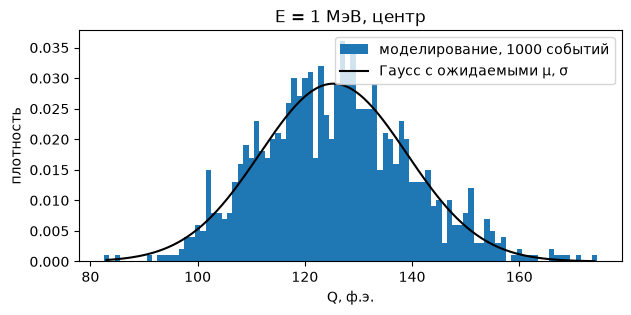

In [2]:
Q1 = simulate_charge(det, src, 1.0, n_events=n_events).sum(axis=1)
f0 = expected_fraction(det).sum()
Qexp = det.a * src.Y * 1.0 * f0
print(f"<Q> = {Q1.mean():.2f} ± {Q1.std()/np.sqrt(n_events):.2f}   ожидание {Qexp:.2f}")
print(f"σ_Q = {Q1.std():.2f}   ожидание {np.sqrt(Qexp*(1+det.a)):.2f}")

bins = np.arange(Q1.min() - 0.5, Q1.max() + 1.5)
plt.figure(figsize=(7, 3))
plt.hist(Q1, bins=bins, density=True, label='моделирование, 1000 событий')
x = np.linspace(Q1.min(), Q1.max(), 200)
s = np.sqrt(Qexp * (1 + det.a))
plt.plot(x, np.exp(-(x - Qexp)**2 / (2*s**2)) / (np.sqrt(2*np.pi)*s), 'k', label='Гаусс с ожидаемыми μ, σ')
plt.xlabel('Q, ф.э.'); plt.ylabel('плотность'); plt.title('E = 1 МэВ, центр'); plt.legend(); plt.show()

## Зависимость от энергии

In [3]:
energies = np.array([0.2, 0.5, 0.7, 1.0, 1.5, 2.0, 3.0])
Q = {E: (Q1 if E == 1.0 else simulate_charge(det, src, E, n_events=n_events).sum(axis=1))
     for E in energies}

mean = np.array([Q[E].mean() for E in energies])
std = np.array([Q[E].std() for E in energies])
rel = std / mean
rel_err = rel / np.sqrt(2 * (n_events - 1))          # ошибка оценки σ ≈ σ/sqrt(2n)
rel_theory = np.sqrt((1 + det.a) / (det.a * src.Y * f0 * energies))

print(" E, МэВ   <Q>      σ_Q    σ/<Q>    теория")
for E, m_, s_, r_, t_ in zip(energies, mean, std, rel, rel_theory):
    print(f"{E:6.1f} {m_:8.1f} {s_:7.2f} {r_:8.4f} {t_:8.4f}")

 E, МэВ   <Q>      σ_Q    σ/<Q>    теория
   0.2     24.9    5.98   0.2400   0.2446
   0.5     62.2    9.79   0.1572   0.1547
   0.7     87.7   11.23   0.1281   0.1308
   1.0    125.8   13.94   0.1108   0.1094
   1.5    187.8   16.70   0.0889   0.0893
   2.0    250.4   18.79   0.0751   0.0774
   3.0    375.2   23.40   0.0624   0.0632


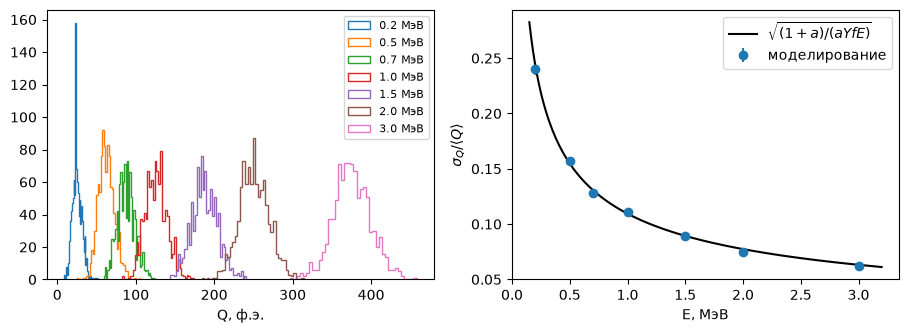

σ/<Q> ∝ E^p,  p = -0.503  (ожидается -0.5);  при 1 МэВ: 0.1085


In [4]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for E in energies:
    ax[0].hist(Q[E], bins=40, histtype='step', label=f'{E} МэВ')
ax[0].set_xlabel('Q, ф.э.'); ax[0].legend(fontsize=8)

ax[1].errorbar(energies, rel, rel_err, fmt='o', label='моделирование')
Eg = np.linspace(0.15, 3.2, 200)
ax[1].plot(Eg, np.sqrt((1 + det.a) / (det.a * src.Y * f0 * Eg)), 'k',
           label=r'$\sqrt{(1+a)/(aYfE)}$')
ax[1].set_xlabel('E, МэВ'); ax[1].set_ylabel(r'$\sigma_Q/\langle Q\rangle$'); ax[1].legend()
plt.show()

# аппроксимация степенной функцией: σ/Q = A E^p
p, logA = np.polyfit(np.log(energies), np.log(rel), 1)
print(f"σ/<Q> ∝ E^p,  p = {p:.3f}  (ожидается -0.5);  при 1 МэВ: {np.exp(logA):.4f}")

**Вывод.** Относительная ширина падает как $1/\sqrt E$: число фотоэлектронов растёт линейно с энергией, а флуктуации пуассоновские. При $a = 0.5$ ширина дополнительно увеличена в $\sqrt{1+a}\approx 1.22$ раза из-за флуктуаций числа ф.э. на фотон. Энергетическое разрешение детектора $\approx 11\%/\sqrt{E[\text{МэВ}]}$.

## Источник смещён на 1 м по оси z

Для точки вне центра доли фотонов на отдельные ФЭУ меняются: ближние катоды видны под большим телесным углом ($\propto \cos\psi/d^2$), дальние — под меньшим. Для **сплошного** покрытия эти изменения в точности компенсируют друг друга (теорема Гаусса: $\oint \cos\psi\, dA/d^2 = 4\pi$ для любой точки внутри), поэтому полный заряд не изменился бы. Для 40 дискретных ФЭУ компенсация неполная, и изменение зависит от того, как ФЭУ расположены относительно источника.

центр:  <Q> = 125.77 ± 0.44   (ожидание 125.31)
z=1 м:  <Q> = 125.02 ± 0.45   (ожидание 125.18)
изменение: моделирование -0.59% ± 0.50%,  ожидание -0.10%


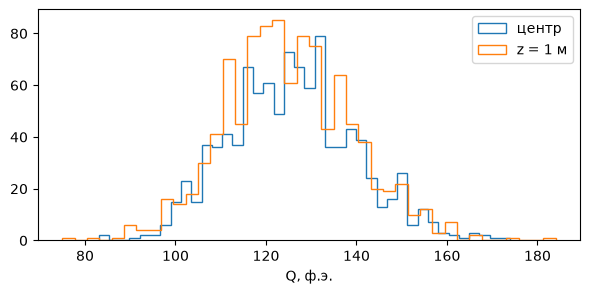

In [5]:
origin = (0, 0, 1.0)
Q1z = simulate_charge(det, src, 1.0, origin=origin, n_events=n_events).sum(axis=1)
f1 = expected_fraction(det, origin).sum()
d_mc = Q1z.mean() / Q1.mean() - 1
d_mc_err = np.sqrt((Q1z.std()/Q1z.mean())**2 + (Q1.std()/Q1.mean())**2) / np.sqrt(n_events)
print(f"центр:  <Q> = {Q1.mean():.2f} ± {Q1.std()/np.sqrt(n_events):.2f}   (ожидание {det.a*src.Y*f0:.2f})")
print(f"z=1 м:  <Q> = {Q1z.mean():.2f} ± {Q1z.std()/np.sqrt(n_events):.2f}   (ожидание {det.a*src.Y*f1:.2f})")
print(f"изменение: моделирование {d_mc:+.2%} ± {d_mc_err:.2%},  ожидание {f1/f0 - 1:+.2%}")

plt.figure(figsize=(7, 3))
plt.hist(Q1, bins=40, histtype='step', label='центр')
plt.hist(Q1z, bins=40, histtype='step', label='z = 1 м')
plt.xlabel('Q, ф.э.'); plt.legend(); plt.show()

Распределение заряда по каналам при этом меняется сильно — это и позволяет восстанавливать положение вершины:

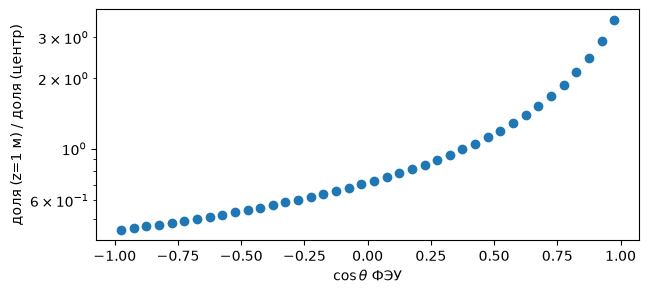

от 0.45 до 3.56


In [6]:
fz = expected_fraction(det, origin)
fc = expected_fraction(det)
cos_theta = det.pmt_directions[:, 2]
plt.figure(figsize=(7, 3))
plt.plot(cos_theta, fz / fc, 'o')
plt.xlabel(r'$\cos\theta$ ФЭУ'); plt.ylabel('доля (z=1 м) / доля (центр)')
plt.yscale('log'); plt.show()
print(f"от {(fz/fc).min():.2f} до {(fz/fc).max():.2f}")

изменение <Q> для смещения на 1 м: среднее +0.00%, разброс 0.32%, от -1.32% до +0.76%


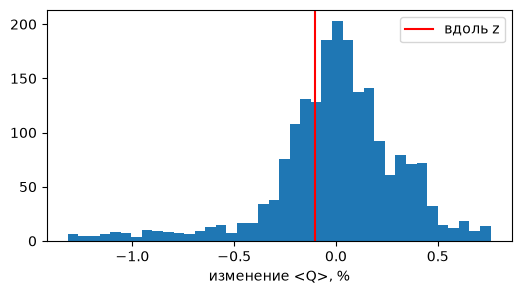

In [7]:
# насколько изменение среднего зависит от направления смещения (1 м в разные стороны)
from detector import fibonacci_sphere
shifts = fibonacci_sphere(2000)
rel_change = np.array([expected_fraction(det, s).sum() for s in shifts]) / f0 - 1
print(f"изменение <Q> для смещения на 1 м: среднее {rel_change.mean():+.2%}, "
      f"разброс {rel_change.std():.2%}, от {rel_change.min():+.2%} до {rel_change.max():+.2%}")
plt.figure(figsize=(6, 3)); plt.hist(rel_change * 100, bins=40)
plt.axvline((f1/f0 - 1) * 100, color='r', label='вдоль z'); plt.legend()
plt.xlabel('изменение <Q>, %'); plt.show()